In [1]:
import pandas, numpy, sklearn.preprocessing, sklearn.metrics, sklearn.model_selection, sklearn.neural_network, imblearn.over_sampling, matplotlib.pyplot, pickle

In [2]:
dataframe = pandas.read_csv("data/ai_workplace_job_risk.csv")
dataframe

,worker_id,industry,job_role,region,company_size,work_mode,education,experience_years,salary_usd_k,routine_task_pct,creativity_score,interpersonal_score,tech_skill_score,automation_exposure_pct,ai_tools_used,ai_hours_week,ai_training_hours_year,company_ai_policy,productivity_gain_pct,job_at_risk
0,W00001,Manufacturing,Manager,Europe,500-4999,Remote,Bachelor,17,66.1,30.4,75.2,39.4,27.4,42.6,0,0.6,14.7,1,18.9,1
1,W00002,Consulting,Researcher,North America,5000+,On-site,High school,3,108.2,47.4,33.7,60.0,77.7,49.4,1,1.6,45.7,1,13.1,0
2,W00003,Healthcare,Writer/Marketer,North America,<50,Hybrid,Bachelor,2,33.1,81.1,65.6,14.0,41.3,63.1,3,2.1,23.6,0,4.2,0
3,W00004,Healthcare,Manager,North America,500-4999,Remote,Master,24,221.5,22.0,63.2,40.8,37.0,30.1,1,1.9,7.4,0,9.6,0
4,W00005,Technology,Designer,Latin America,500-4999,Hybrid,Bachelor,3,98.2,51.6,53.5,54.1,38.0,44.2,2,0.4,9.8,0,14.8,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,W09996,Education,Researcher,Asia Pacific,5000+,Hybrid,Bachelor,19,135.1,20.0,47.1,46.6,62.3,31.7,3,7.1,41.4,1,23.4,0
9996,W09997,Technology,Operations,Europe,500-4999,On-site,Bachelor,21,153.6,70.3,23.0,57.5,38.1,68.3,1,2.7,11.5,1,14.4,1
9997,W09998,Healthcare,Engineer,North America,5000+,Remote,Bachelor,5,21.1,42.4,72.3,75.8,58.7,28.7,1,4.9,19.3,1,17.0,0
9998,W09999,Retail,Writer/Marketer,North America,500-4999,Remote,Bachelor,9,34.5,33.1,55.6,44.4,46.4,36.0,0,2.6,5.8,0,18.4,0


In [3]:
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   worker_id                10000 non-null  str    
 1   industry                 10000 non-null  str    
 2   job_role                 10000 non-null  str    
 3   region                   10000 non-null  str    
 4   company_size             10000 non-null  str    
 5   work_mode                10000 non-null  str    
 6   education                10000 non-null  str    
 7   experience_years         10000 non-null  int64  
 8   salary_usd_k             10000 non-null  float64
 9   routine_task_pct         10000 non-null  float64
 10  creativity_score         10000 non-null  float64
 11  interpersonal_score      10000 non-null  float64
 12  tech_skill_score         10000 non-null  float64
 13  automation_exposure_pct  10000 non-null  float64
 14  ai_tools_used            10000 non

In [4]:
dataframe.describe()

,experience_years,salary_usd_k,routine_task_pct,creativity_score,interpersonal_score,tech_skill_score,automation_exposure_pct,ai_tools_used,ai_hours_week,ai_training_hours_year,company_ai_policy,productivity_gain_pct,job_at_risk
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.00000,10000.000000,10000.000000,10000.00000
mean,8.080200,86.372290,51.201530,54.377360,49.609640,56.000280,49.647400,1.985900,3.90574,22.53043,0.597900,15.636200,0.30000
std,7.850983,34.005362,20.299913,16.349464,18.310726,18.106765,15.680392,1.640479,4.25280,16.71489,0.490346,6.818113,0.45828
min,0.000000,19.600000,5.000000,5.000000,5.000000,5.000000,3.000000,0.000000,0.10000,0.20000,0.000000,0.000000,0.00000
25%,2.000000,62.500000,36.700000,43.300000,37.100000,43.500000,38.800000,1.000000,1.40000,10.60000,0.000000,11.000000,0.00000
50%,6.000000,80.300000,51.400000,54.300000,49.500000,56.000000,49.600000,2.000000,2.60000,18.30000,1.000000,15.300000,0.00000
75%,11.000000,103.500000,65.900000,65.425000,62.200000,68.500000,60.800000,3.000000,4.70000,30.10000,1.000000,19.900000,1.00000
max,40.000000,370.700000,95.000000,100.000000,100.000000,100.000000,97.900000,11.000000,40.00000,152.50000,1.000000,49.900000,1.00000


In [5]:
dataframe = dataframe.drop(["worker_id"], axis=1)
dataframe

,industry,job_role,region,company_size,work_mode,education,experience_years,salary_usd_k,routine_task_pct,creativity_score,interpersonal_score,tech_skill_score,automation_exposure_pct,ai_tools_used,ai_hours_week,ai_training_hours_year,company_ai_policy,productivity_gain_pct,job_at_risk
0,Manufacturing,Manager,Europe,500-4999,Remote,Bachelor,17,66.1,30.4,75.2,39.4,27.4,42.6,0,0.6,14.7,1,18.9,1
1,Consulting,Researcher,North America,5000+,On-site,High school,3,108.2,47.4,33.7,60.0,77.7,49.4,1,1.6,45.7,1,13.1,0
2,Healthcare,Writer/Marketer,North America,<50,Hybrid,Bachelor,2,33.1,81.1,65.6,14.0,41.3,63.1,3,2.1,23.6,0,4.2,0
3,Healthcare,Manager,North America,500-4999,Remote,Master,24,221.5,22.0,63.2,40.8,37.0,30.1,1,1.9,7.4,0,9.6,0
4,Technology,Designer,Latin America,500-4999,Hybrid,Bachelor,3,98.2,51.6,53.5,54.1,38.0,44.2,2,0.4,9.8,0,14.8,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,Education,Researcher,Asia Pacific,5000+,Hybrid,Bachelor,19,135.1,20.0,47.1,46.6,62.3,31.7,3,7.1,41.4,1,23.4,0
9996,Technology,Operations,Europe,500-4999,On-site,Bachelor,21,153.6,70.3,23.0,57.5,38.1,68.3,1,2.7,11.5,1,14.4,1
9997,Healthcare,Engineer,North America,5000+,Remote,Bachelor,5,21.1,42.4,72.3,75.8,58.7,28.7,1,4.9,19.3,1,17.0,0
9998,Retail,Writer/Marketer,North America,500-4999,Remote,Bachelor,9,34.5,33.1,55.6,44.4,46.4,36.0,0,2.6,5.8,0,18.4,0


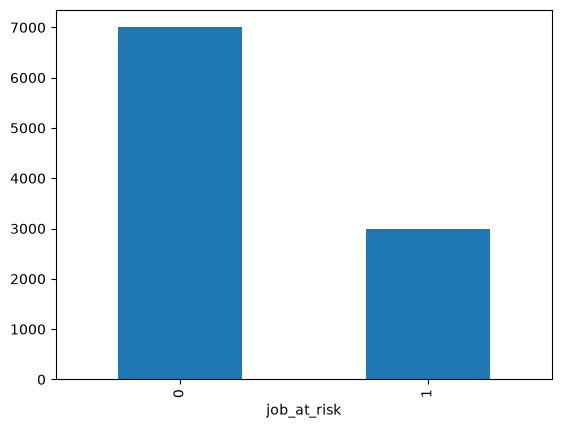

In [6]:
dataframe[dataframe.columns[-1]].value_counts().plot(kind="bar")
matplotlib.pyplot.show()

In [7]:
scaler = sklearn.preprocessing.StandardScaler()
scaler

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [8]:
industry_encoder = sklearn.preprocessing.OrdinalEncoder(categories=[dataframe["industry"].unique().tolist()], handle_unknown="use_encoded_value", unknown_value=numpy.nan)
job_role_encoder = sklearn.preprocessing.OrdinalEncoder(categories=[dataframe["job_role"].unique().tolist()], handle_unknown="use_encoded_value", unknown_value=numpy.nan)
region_encoder = sklearn.preprocessing.OrdinalEncoder(categories=[dataframe["region"].unique().tolist()], handle_unknown="use_encoded_value", unknown_value=numpy.nan)
company_size_encoder = sklearn.preprocessing.OrdinalEncoder(categories=[dataframe["company_size"].unique().tolist()], handle_unknown="use_encoded_value", unknown_value=numpy.nan)
work_mode_encoder = sklearn.preprocessing.OrdinalEncoder(categories=[dataframe["work_mode"].unique().tolist()], handle_unknown="use_encoded_value", unknown_value=numpy.nan)
education_encoder = sklearn.preprocessing.OrdinalEncoder(categories=[dataframe["education"].unique().tolist()], handle_unknown="use_encoded_value", unknown_value=numpy.nan)

In [9]:
smote = imblearn.over_sampling.SMOTE(sampling_strategy="minority", random_state=42)
smote

,sampling_strategy,'minority'
,random_state,42
,k_neighbors,5


In [10]:
dataframe = dataframe.drop("productivity_gain_pct", axis=1)
dataframe

,industry,job_role,region,company_size,work_mode,education,experience_years,salary_usd_k,routine_task_pct,creativity_score,interpersonal_score,tech_skill_score,automation_exposure_pct,ai_tools_used,ai_hours_week,ai_training_hours_year,company_ai_policy,job_at_risk
0,Manufacturing,Manager,Europe,500-4999,Remote,Bachelor,17,66.1,30.4,75.2,39.4,27.4,42.6,0,0.6,14.7,1,1
1,Consulting,Researcher,North America,5000+,On-site,High school,3,108.2,47.4,33.7,60.0,77.7,49.4,1,1.6,45.7,1,0
2,Healthcare,Writer/Marketer,North America,<50,Hybrid,Bachelor,2,33.1,81.1,65.6,14.0,41.3,63.1,3,2.1,23.6,0,0
3,Healthcare,Manager,North America,500-4999,Remote,Master,24,221.5,22.0,63.2,40.8,37.0,30.1,1,1.9,7.4,0,0
4,Technology,Designer,Latin America,500-4999,Hybrid,Bachelor,3,98.2,51.6,53.5,54.1,38.0,44.2,2,0.4,9.8,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,Education,Researcher,Asia Pacific,5000+,Hybrid,Bachelor,19,135.1,20.0,47.1,46.6,62.3,31.7,3,7.1,41.4,1,0
9996,Technology,Operations,Europe,500-4999,On-site,Bachelor,21,153.6,70.3,23.0,57.5,38.1,68.3,1,2.7,11.5,1,1
9997,Healthcare,Engineer,North America,5000+,Remote,Bachelor,5,21.1,42.4,72.3,75.8,58.7,28.7,1,4.9,19.3,1,0
9998,Retail,Writer/Marketer,North America,500-4999,Remote,Bachelor,9,34.5,33.1,55.6,44.4,46.4,36.0,0,2.6,5.8,0,0


In [11]:
X = dataframe[dataframe.columns[0:-1]]
Y = dataframe[dataframe.columns[-1]]

In [12]:
X_train, X_test, Y_train, Y_test = sklearn.model_selection.train_test_split(X, Y, stratify=Y, test_size=0.3, random_state=42)

In [13]:
X_train.columns

Index(['industry', 'job_role', 'region', 'company_size', 'work_mode',
       'education', 'experience_years', 'salary_usd_k', 'routine_task_pct',
       'creativity_score', 'interpersonal_score', 'tech_skill_score',
       'automation_exposure_pct', 'ai_tools_used', 'ai_hours_week',
       'ai_training_hours_year', 'company_ai_policy'],
      dtype='str')

In [14]:
X_train["industry"] = industry_encoder.fit_transform(X_train[["industry"]])
X_train["job_role"] = job_role_encoder.fit_transform(X_train[["job_role"]])
X_train["region"] = region_encoder.fit_transform(X_train[["region"]])
X_train["company_size"] = company_size_encoder.fit_transform(X_train[["company_size"]])
X_train["work_mode"] = work_mode_encoder.fit_transform(X_train[["work_mode"]])
X_train["education"] = education_encoder.fit_transform(X_train[["education"]])
X_test["industry"] = industry_encoder.transform(X_test[["industry"]])
X_test["job_role"] = job_role_encoder.transform(X_test[["job_role"]])
X_test["region"] = region_encoder.transform(X_test[["region"]])
X_test["company_size"] = company_size_encoder.transform(X_test[["company_size"]])
X_test["work_mode"] = work_mode_encoder.transform(X_test[["work_mode"]])
X_test["education"] = education_encoder.transform(X_test[["education"]])

In [15]:
X_train = pandas.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pandas.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

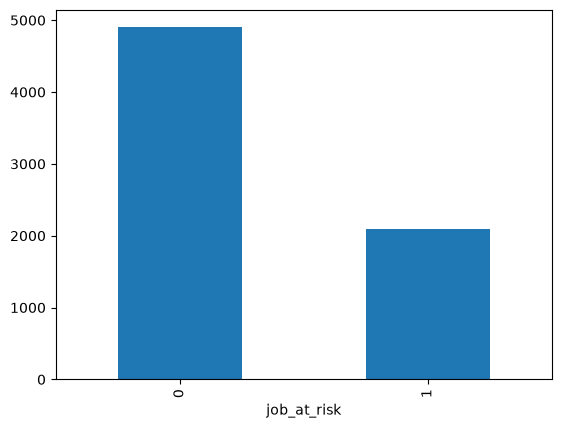

In [16]:
Y_train.value_counts().plot(kind="bar")
matplotlib.pyplot.show()

In [17]:
X_train, Y_train = smote.fit_resample(X_train, Y_train)

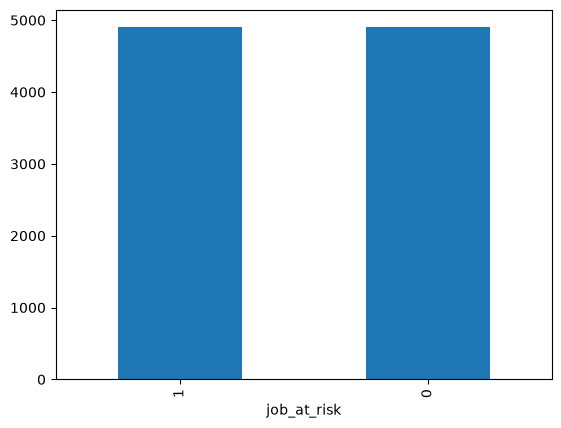

In [18]:
Y_train.value_counts().plot(kind="bar")
matplotlib.pyplot.show()

In [19]:
model = sklearn.neural_network.MLPClassifier(
    hidden_layer_sizes=(128, ), 
    activation="relu",
    learning_rate="constant", 
    solver="adam", 
    learning_rate_init=0.1, 
    alpha=0.1, 
    max_iter=5_000,
    early_stopping=True, 
    random_state=42
)
model

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(128,)"
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.1
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.1
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",5000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by at least``tol`` for ``n_iter_no_change`` consecutive epochs. The split isstratified, except in a multilabel setting.If early stopping is False, then the training stops when the trainingloss does not improve by more than ``tol`` for ``n_iter_no_change``consecutive passes over the training set.Only effective when solver='sgd' or 'adam'.",True
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divide

In [20]:
model.fit(X_train, Y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(128,)"
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.1
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.1
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",5000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by at least``tol`` for ``n_iter_no_change`` consecutive epochs. The split isstratified, except in a multilabel setting.If early stopping is False, then the training stops when the trainingloss does not improve by more than ``tol`` for ``n_iter_no_change``consecutive passes over the training set.Only effective when solver='sgd' or 'adam'.",True
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divide

In [21]:
sklearn.metrics.accuracy_score(Y_test, model.predict(X_test))

0.8023333333333333

In [22]:
print(sklearn.metrics.classification_report(Y_test, model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.87      0.84      0.86      2100
           1       0.66      0.71      0.68       900

    accuracy                           0.80      3000
   macro avg       0.76      0.78      0.77      3000
weighted avg       0.81      0.80      0.80      3000



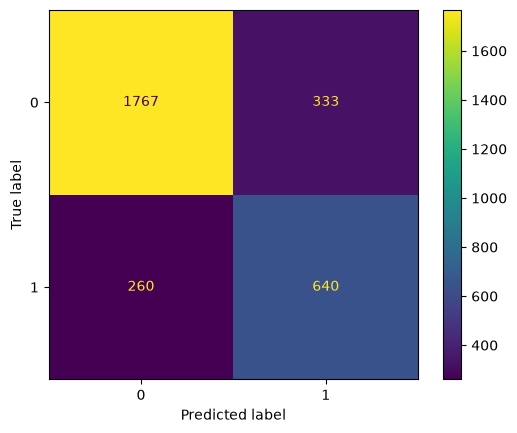

In [23]:
sklearn.metrics.ConfusionMatrixDisplay(sklearn.metrics.confusion_matrix(Y_test, model.predict(X_test))).plot()
matplotlib.pyplot.show()

In [24]:
sklearn.metrics.accuracy_score(Y_train, model.predict(X_train))

0.8072448979591836

In [25]:
print(sklearn.metrics.classification_report(Y_train, model.predict(X_train)))

              precision    recall  f1-score   support

           0       0.79      0.84      0.81      4900
           1       0.83      0.78      0.80      4900

    accuracy                           0.81      9800
   macro avg       0.81      0.81      0.81      9800
weighted avg       0.81      0.81      0.81      9800



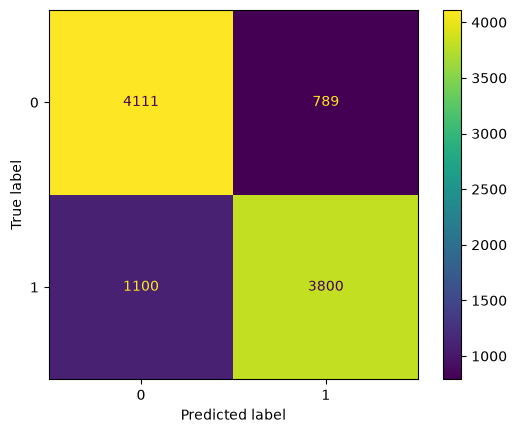

In [26]:
sklearn.metrics.ConfusionMatrixDisplay(sklearn.metrics.confusion_matrix(Y_train, model.predict(X_train))).plot()
matplotlib.pyplot.show()

In [27]:
X["industry"] = industry_encoder.fit_transform(X[["industry"]])
X["job_role"] = job_role_encoder.fit_transform(X[["job_role"]])
X["region"] = region_encoder.fit_transform(X[["region"]])
X["company_size"] = company_size_encoder.fit_transform(X[["company_size"]])
X["work_mode"] = work_mode_encoder.fit_transform(X[["work_mode"]])
X["education"] = education_encoder.fit_transform(X[["education"]])

In [28]:
X = pandas.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

In [29]:
model.fit(X, Y)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(128,)"
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.1
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.1
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",5000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by at least``tol`` for ``n_iter_no_change`` consecutive epochs. The split isstratified, except in a multilabel setting.If early stopping is False, then the training stops when the trainingloss does not improve by more than ``tol`` for ``n_iter_no_change``consecutive passes over the training set.Only effective when solver='sgd' or 'adam'.",True
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divide

In [30]:
sklearn.metrics.accuracy_score(Y, model.predict(X))

0.8191

In [31]:
print(sklearn.metrics.classification_report(Y, model.predict(X)))

              precision    recall  f1-score   support

           0       0.82      0.95      0.88      7000
           1       0.82      0.51      0.63      3000

    accuracy                           0.82     10000
   macro avg       0.82      0.73      0.75     10000
weighted avg       0.82      0.82      0.80     10000



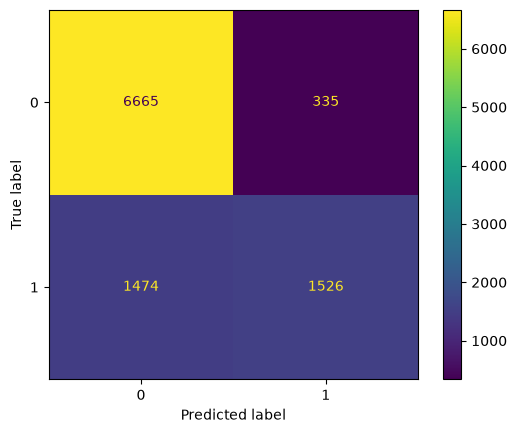

In [32]:
sklearn.metrics.ConfusionMatrixDisplay(sklearn.metrics.confusion_matrix(Y, model.predict(X))).plot()
matplotlib.pyplot.show()

In [33]:
with open("models/ai_job_risk_model.pickle", "wb+") as file:
    pickle.dump((industry_encoder, job_role_encoder, region_encoder, company_size_encoder, work_mode_encoder, education_encoder, scaler, model), file)